# Atividade prática - Diagnóstico de câncer de mama com MLP

A ideia aqui é treinar uma rede neural (MLPClassifier) pra classificar tumores em benigno ou maligno usando o dataset Breast Cancer do sklearn, e ver o que acontece quando a gente treina sem escalonar os dados e depois com o StandardScaler.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")  # o modelo sem escala costuma dar aviso de convergencia

### 1. Carregando os dados

In [2]:
dados = load_breast_cancer()
X = dados.data
y = dados.target

print("formato do X:", X.shape)
print("classes:", dados.target_names)
print("qtd de cada classe:", np.bincount(y))

formato do X: (569, 30)
classes: ['malignant' 'benign']
qtd de cada classe: [212 357]


Dando uma olhada nas escalas das features, dá pra ver que elas são bem diferentes entre si (tem coisa na casa de 0.0x e outras passando de 1000):

In [3]:
print("menor valor de cada coluna (5 primeiras):", X.min(axis=0)[:5].round(3))
print("maior valor de cada coluna (5 primeiras):", X.max(axis=0)[:5].round(3))
print()
print("feature com maior valor maximo:", dados.feature_names[X.max(axis=0).argmax()], "->", X.max(axis=0).max())
print("feature com menor valor maximo:", dados.feature_names[X.max(axis=0).argmin()], "->", X.max(axis=0).min())

menor valor de cada coluna (5 primeiras): [6.981e+00 9.710e+00 4.379e+01 1.435e+02 5.300e-02]
maior valor de cada coluna (5 primeiras): [2.811e+01 3.928e+01 1.885e+02 2.501e+03 1.630e-01]

feature com maior valor maximo: worst area -> 4254.0
feature com menor valor maximo: fractal dimension error -> 0.02984


### 2. Separando treino (70%) e teste (30%)

Usei stratify pra manter a proporção de benigno/maligno nos dois conjuntos.

In [4]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("treino:", X_treino.shape[0], "amostras")
print("teste:", X_teste.shape[0], "amostras")

treino: 398 amostras
teste: 171 amostras


### 3. MLP sem escalonar os dados

In [5]:
mlp_sem = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)
mlp_sem.fit(X_treino, y_treino)

pred_sem = mlp_sem.predict(X_teste)
acc_sem = accuracy_score(y_teste, pred_sem)

print("acuracia SEM escalonamento:", round(acc_sem, 4))
print("iteracoes ate parar:", mlp_sem.n_iter_)
print("loss final:", round(mlp_sem.loss_, 4))

acuracia SEM escalonamento: 0.9181
iteracoes ate parar: 279
loss final: 0.1451


### 4. Agora com StandardScaler

O scaler é ajustado só no treino (fit) e depois aplicado no teste, pra não vazar informação do teste pro modelo.

In [6]:
scaler = StandardScaler()
X_treino_esc = scaler.fit_transform(X_treino)
X_teste_esc = scaler.transform(X_teste)

mlp_com = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)
mlp_com.fit(X_treino_esc, y_treino)

pred_com = mlp_com.predict(X_teste_esc)
acc_com = accuracy_score(y_teste, pred_com)

print("acuracia COM escalonamento:", round(acc_com, 4))
print("iteracoes ate parar:", mlp_com.n_iter_)
print("loss final:", round(mlp_com.loss_, 4))

acuracia COM escalonamento: 0.9708
iteracoes ate parar: 352
loss final: 0.0062


### 5. Comparando os dois cenários

In [7]:
print(f"{'':20}{'sem escala':>12}{'com escala':>12}")
print(f"{'acuracia':20}{acc_sem:>12.4f}{acc_com:>12.4f}")
print(f"{'iteracoes':20}{mlp_sem.n_iter_:>12}{mlp_com.n_iter_:>12}")
print(f"{'loss final':20}{mlp_sem.loss_:>12.4f}{mlp_com.loss_:>12.4f}")

                      sem escala  com escala
acuracia                  0.9181      0.9708
iteracoes                    279         352
loss final                0.1451      0.0062


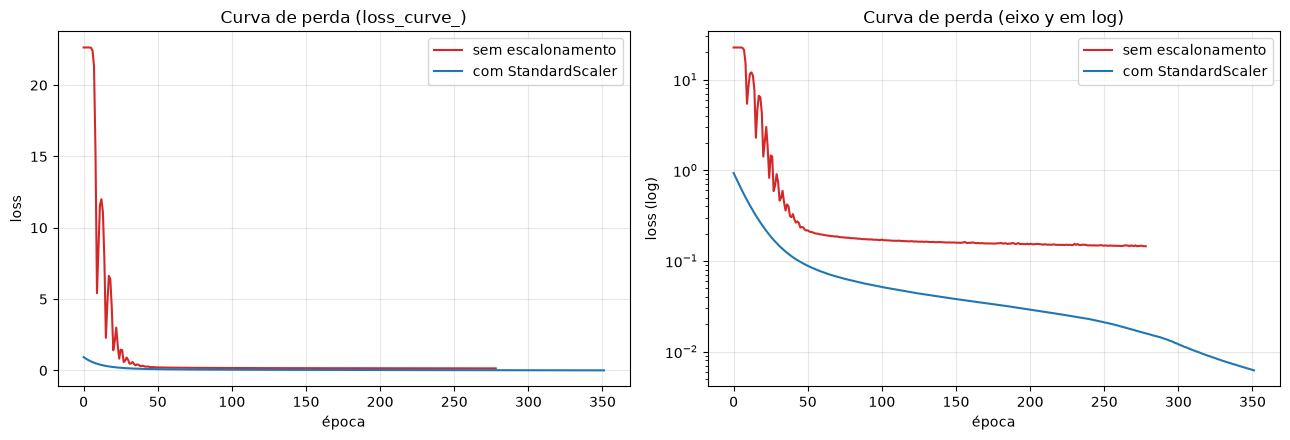

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(mlp_sem.loss_curve_, label="sem escalonamento", color="tab:red")
axes[0].plot(mlp_com.loss_curve_, label="com StandardScaler", color="tab:blue")
axes[0].set_title("Curva de perda (loss_curve_)")
axes[0].set_xlabel("época")
axes[0].set_ylabel("loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# mesma coisa em escala log, porque a curva sem escala começa muito alta e achata a outra
axes[1].plot(mlp_sem.loss_curve_, label="sem escalonamento", color="tab:red")
axes[1].plot(mlp_com.loss_curve_, label="com StandardScaler", color="tab:blue")
axes[1].set_yscale("log")
axes[1].set_title("Curva de perda (eixo y em log)")
axes[1].set_xlabel("época")
axes[1].set_ylabel("loss (log)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Rodando os dois modelos com a mesma arquitetura e a mesma semente, a diferença ficou bem clara:

- **Sem escalonamento:** acurácia de **91,81%** no teste. A perda começou em torno de 22,6, ficou pulando bastante nas primeiras épocas e só passou de 0,2 para baixo na época 57. Depois disso travou perto de 0,15 e o treino parou na época 279 porque a perda não melhorava mais.
- **Com StandardScaler:** acurácia de **97,08%** no teste. A perda já começou abaixo de 1, caiu de forma suave e passou de 0,2 para baixo na época 24 (mais que o dobro de rápido). Ela continuou descendo até 0,006 na época 352.

Um ponto que pode confundir é que o modelo sem escala parou com menos iterações (279 contra 352). Isso não quer dizer que ele convergiu mais rápido. Ele estacionou numa perda alta e o sklearn encerrou o treino por falta de melhora. O modelo escalonado continuou aprendendo por mais tempo porque ainda tinha espaço para melhorar, e terminou com uma perda umas 20 vezes menor.

Ou seja, a rede é a mesma. O que mudou foi só a escala da entrada, e isso foi suficiente para mudar a velocidade de convergência e o resultado final (cerca de 5 pontos percentuais a mais de acurácia).

## Análise crítica

**Por que o escalonamento dos dados é tão importante pra otimização via gradiente descendente em redes neurais?**

No dataset de câncer de mama as features estão em escalas muito diferentes. A área do tumor, por exemplo, passa de 2000, enquanto algumas medidas de suavidade e simetria ficam abaixo de 0.1. Quando a rede recebe isso direto, algumas coisas dão errado:

1. **Gradientes desbalanceados.** O gradiente de cada peso da primeira camada é proporcional ao valor da entrada ligada a ele. Então os pesos ligados às features grandes recebem atualizações enormes e os ligados às features pequenas quase não se mexem. Com uma taxa de aprendizado única pra todos, ou ela é pequena demais pras features pequenas ou grande demais pras grandes.

2. **Superfície de erro alongada.** Com escalas diferentes, a função de perda fica com formato de um "vale" muito esticado em vez de algo mais arredondado. O gradiente aponta mais para as paredes do vale do que para o mínimo, então o otimizador fica fazendo zigue-zague e demora pra chegar no fundo. Isso aparece na curva vermelha, que oscila e desce devagar.

3. **Neurônios dominados por poucas features.** Entradas muito grandes geram somas ponderadas grandes. Com a ReLU (padrão do MLPClassifier) isso pode deixar neurônios "mortos" ou com a ativação dominada por uma ou duas variáveis, e a rede acaba ignorando informação útil das outras.

4. **Inicialização dos pesos.** A inicialização usada pelo sklearn (Glorot) parte do princípio de que as entradas têm média perto de zero e variância perto de 1. Sem escalonar, essa suposição quebra e o treino já começa num ponto ruim.

O StandardScaler deixa cada feature com média 0 e desvio padrão 1, então todas passam a contribuir de forma parecida pro gradiente. A superfície de erro fica mais "redonda", o gradiente aponta mais na direção certa e o modelo converge em menos épocas e chega numa solução melhor, que foi o que apareceu na comparação acima.

Um detalhe importante é que o scaler tem que ser ajustado só nos dados de treino. Se ajustar com o dataset inteiro, a média e o desvio do teste vazam pro treinamento e a acurácia fica otimista demais.